Found 2144 images belonging to 3 classes.
Found 458 images belonging to 3 classes.
Found 462 images belonging to 3 classes.
Epoch 1/10


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


67/67 - 664s - 10s/step - accuracy: 0.7509 - loss: 0.5817 - val_accuracy: 0.8624 - val_loss: 0.3708
Epoch 2/10
67/67 - 671s - 10s/step - accuracy: 0.8680 - loss: 0.3118 - val_accuracy: 0.8755 - val_loss: 0.3163
Epoch 3/10
67/67 - 768s - 11s/step - accuracy: 0.8932 - loss: 0.2735 - val_accuracy: 0.8908 - val_loss: 0.2763
Epoch 4/10
67/67 - 799s - 12s/step - accuracy: 0.9067 - loss: 0.2226 - val_accuracy: 0.8777 - val_loss: 0.2898
Epoch 5/10
67/67 - 778s - 12s/step - accuracy: 0.9319 - loss: 0.1815 - val_accuracy: 0.8996 - val_loss: 0.2517
Epoch 6/10
67/67 - 768s - 11s/step - accuracy: 0.9356 - loss: 0.1572 - val_accuracy: 0.9127 - val_loss: 0.2228
Epoch 7/10
67/67 - 790s - 12s/step - accuracy: 0.9510 - loss: 0.1328 - val_accuracy: 0.9170 - val_loss: 0.2199
Epoch 8/10
67/67 - 784s - 12s/step - accuracy: 0.9599 - loss: 0.1158 - val_accuracy: 0.9192 - val_loss: 0.2573
Epoch 9/10
67/67 - 747s - 11s/step - accuracy: 0.9627 - loss: 0.1030 - val_accuracy: 0.8624 - val_loss: 0.2811
Epoch 10/10


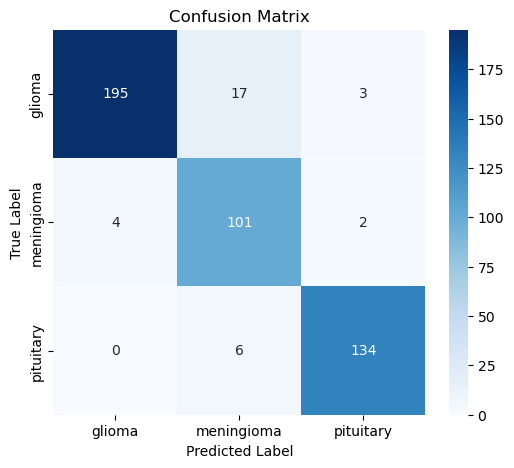

ValueError: y should be a 1d array, got an array of shape (462, 3) instead.

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, Flatten
from tensorflow.keras.applications import VGG16
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, roc_curve, auc, confusion_matrix, classification_report
import seaborn as sns
import os

# Base data directory
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'

# Paths
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# Image parameters
img_height, img_width = 224, 224
batch_size = 32

# ImageDataGenerator
datagen = ImageDataGenerator(rescale=1./255)

train_data = datagen.flow_from_directory(train_dir, target_size=(img_height, img_width),
                                         batch_size=batch_size, class_mode='categorical', shuffle=True)
val_data = datagen.flow_from_directory(val_dir, target_size=(img_height, img_width),
                                       batch_size=batch_size, class_mode='categorical', shuffle=True)
test_data = datagen.flow_from_directory(test_dir, target_size=(img_height, img_width),
                                        batch_size=batch_size, class_mode='categorical', shuffle=False)

# Load VGG16 base model
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))
base_model.trainable = False  # freeze layers

# Build model on top
x = base_model.output
x = Flatten()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(3, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

# Compile model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

# Early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Train model
history = model.fit(train_data, epochs=10, validation_data=val_data, callbacks=[early_stopping], verbose=2)

# Evaluate on test set
test_loss, test_acc = model.evaluate(test_data)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Predictions
test_labels = test_data.classes
test_preds = model.predict(test_data)
test_preds_labels = np.argmax(test_preds, axis=1)

# Confusion matrix & classification report
conf_matrix = confusion_matrix(test_labels, test_preds_labels)
print("\nConfusion Matrix:")
print(conf_matrix)

print("\nClassification Report:")
print(classification_report(test_labels, test_preds_labels, target_names=test_data.class_indices.keys()))

# Confusion matrix plot
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_data.class_indices.keys(),
            yticklabels=test_data.class_indices.keys())
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Precision-Recall Curve (for class index 2)
precision, recall, _ = precision_recall_curve(test_labels == 2, test_preds == 2)
pr_auc = auc(recall, precision)
print(f"🔢 Precision-Recall AUC for class 2: {pr_auc:.2f}")

plt.figure()
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {pr_auc:.2f})', color='green')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(test_labels == 2, test_preds == 2)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='darkorange')
plt.plot([0, 1], [0, 1], linestyle='--', color='navy')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Accuracy & Loss curves
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


In [2]:
model.save('VGG16 model_10 Epochs.h5')  # Save the model
print("Model saved successfully!")

Model saved successfully!


In [1]:
import time
import os
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# === PATHS ===
model_path = r"C:\Users\usER\Downloads\VGG16 model_10 Epochs.h5"
image_path = r"C:\Users\usER\Downloads\1512427\converted_images_split\test\glioma\3061.jpg"

# === Load Model ===
model = load_model(model_path)
print("✅ Model loaded successfully.")

# === Load and Preprocess Image ===
img = load_img(image_path, target_size=(224, 224))  # adjust to your model input
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)  # shape: (1, 224, 224, 3)

# === Measure Inference Time ===
start = time.time()
_ = model.predict(img_array)
end = time.time()

inference_time_ms = (end - start) * 1000
print(f"🕒 Inference Time: {inference_time_ms:.2f} ms")

# === Measure Model Size ===
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"💾 Model Size: {model_size_mb:.2f} MB")


✅ Model loaded successfully.
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
🕒 Inference Time: 1551.07 ms
💾 Model Size: 203.25 MB


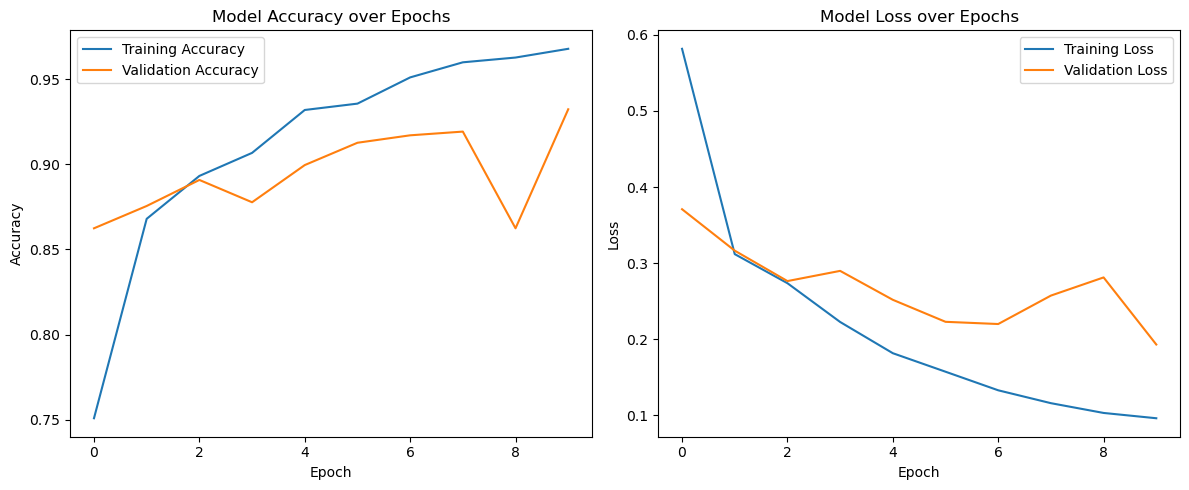

In [3]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot training & validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


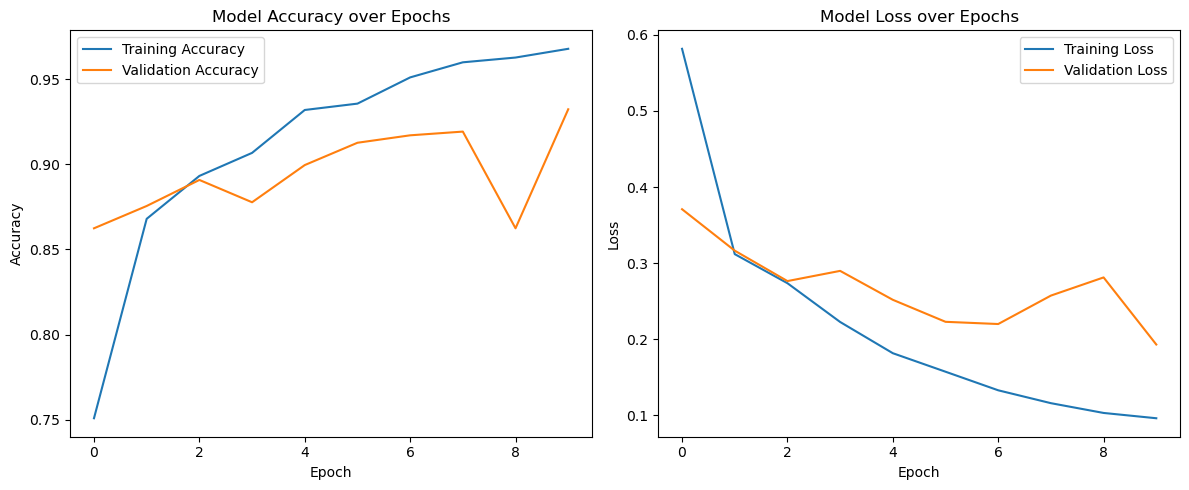

In [12]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot training & validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()



Found 462 images belonging to 3 classes.


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


15/15 ━━━━━━━━━━━━━━━━━━━━ 111s 7s/step

Confusion Matrix:
[[195  17   3]
 [  4 101   2]
 [  0   6 134]]

Classification Report:
              precision    recall  f1-score   support

      glioma       0.98      0.91      0.94       215
  meningioma       0.81      0.94      0.87       107
   pituitary       0.96      0.96      0.96       140

    accuracy                           0.93       462
   macro avg       0.92      0.94      0.93       462
weighted avg       0.94      0.93      0.93       462



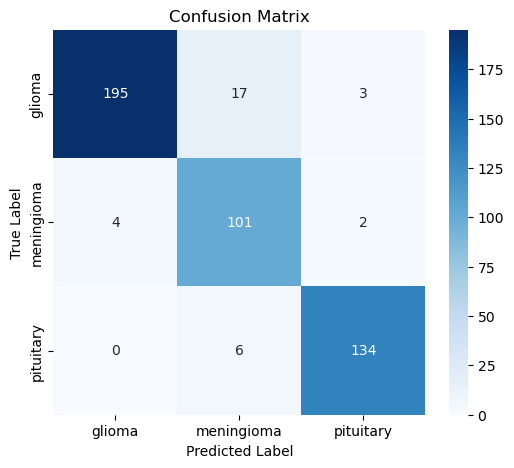

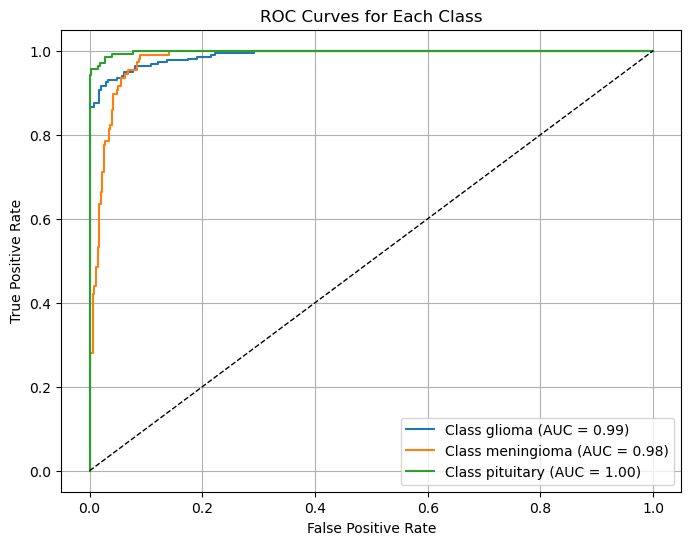

In [15]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import roc_curve, auc, classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ====== Load the model ======
model = load_model('VGG16 model_10 Epochs.h5')

# ====== Set paths and image parameters ======
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'
test_dir = os.path.join(base_dir, 'test')
img_height, img_width = 224, 224
batch_size = 32

# ====== Load test data ======
datagen = ImageDataGenerator(rescale=1./255)
test_data = datagen.flow_from_directory(test_dir, target_size=(img_height, img_width),
                                        batch_size=batch_size, class_mode='categorical', shuffle=False)

# ====== Get true and predicted labels ======
test_labels = test_data.classes
class_names = list(test_data.class_indices.keys())
test_preds = model.predict(test_data)
test_preds_labels = np.argmax(test_preds, axis=1)

# ====== Confusion Matrix and Report ======
conf_matrix = confusion_matrix(test_labels, test_preds_labels)
print("\nConfusion Matrix:")
print(conf_matrix)

print("\nClassification Report:")
print(classification_report(test_labels, test_preds_labels, target_names=class_names))

# ====== Plot Confusion Matrix ======
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# ====== ROC Curve for each class ======
from sklearn.preprocessing import label_binarize

# Binarize the labels for multi-class ROC
n_classes = len(class_names)
y_true_bin = label_binarize(test_labels, classes=range(n_classes))
fpr = dict()
tpr = dict()
roc_auc = dict()

# Compute ROC and AUC for each class
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], test_preds[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'Class {class_names[i]} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Each Class')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


Found 462 images belonging to 3 classes.


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


15/15 ━━━━━━━━━━━━━━━━━━━━ 116s 8s/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.98      0.91      0.94       215
  meningioma       0.81      0.94      0.87       107
   pituitary       0.96      0.96      0.96       140

    accuracy                           0.93       462
   macro avg       0.92      0.94      0.93       462
weighted avg       0.94      0.93      0.93       462



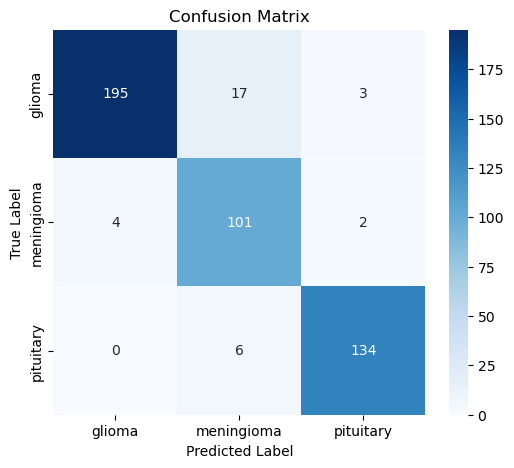

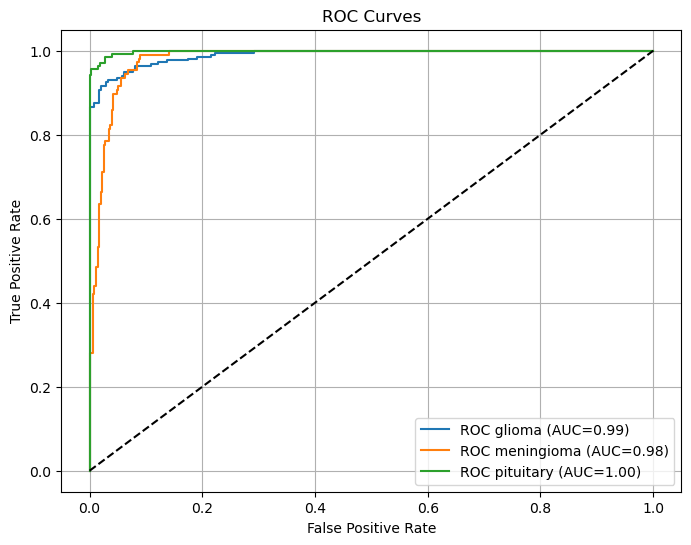

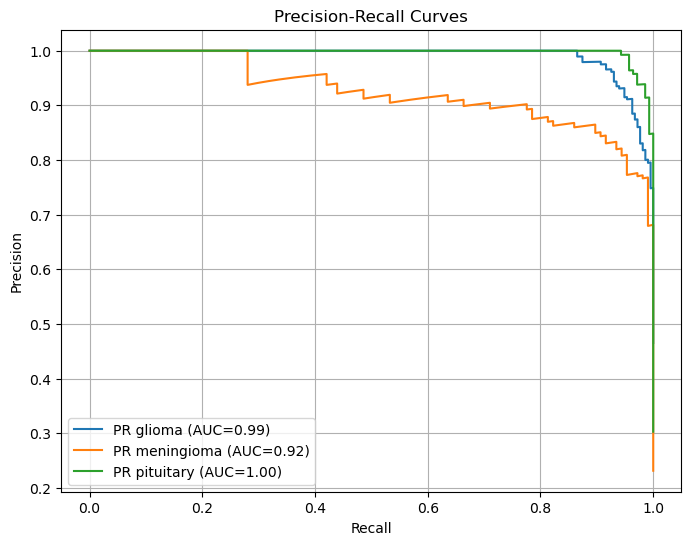

In [16]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load model
model = load_model('VGG16 model_10 Epochs.h5')

# Data setup
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'
test_dir = os.path.join(base_dir, 'test')
img_height, img_width = 224, 224
batch_size = 32

datagen = ImageDataGenerator(rescale=1./255)
test_data = datagen.flow_from_directory(test_dir, target_size=(img_height, img_width),
                                        batch_size=batch_size, class_mode='categorical', shuffle=False)

test_labels = test_data.classes
class_names = list(test_data.class_indices.keys())
n_classes = len(class_names)

# Predictions
test_preds = model.predict(test_data)
test_preds_labels = np.argmax(test_preds, axis=1)

# Confusion matrix & report (optional)
from sklearn.metrics import confusion_matrix, classification_report
conf_matrix = confusion_matrix(test_labels, test_preds_labels)
print("\nClassification Report:")
print(classification_report(test_labels, test_preds_labels, target_names=class_names))

# Plot Confusion Matrix (optional)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Binarize labels for multi-class metrics
y_true_bin = label_binarize(test_labels, classes=range(n_classes))

# ROC Curve and AUC per class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], test_preds[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'ROC {class_names[i]} (AUC={roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Precision-Recall Curve and AUC per class
precision = dict()
recall = dict()
pr_auc = dict()
for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], test_preds[:, i])
    pr_auc[i] = auc(recall[i], precision[i])

plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(recall[i], precision[i], label=f'PR {class_names[i]} (AUC={pr_auc[i]:.2f})')
plt.title('Precision-Recall Curves')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()


In [1]:
import numpy as np

# ============================================================
# Confusion Matrix
# Rows    = Actual classes
# Columns = Predicted classes
#
# Classes:
# 0 = Glioma
# 1 = Meningioma
# 2 = Pituitary
# ============================================================

cm = np.array([
    [195, 17, 3],
    [4, 101, 2],
    [0, 6, 134]
])

class_names = ["Glioma", "Meningioma", "Pituitary"]

# Total number of samples
total = np.sum(cm)

sensitivity = []
specificity = []

print("=" * 65)
print("SENSITIVITY AND SPECIFICITY RESULTS")
print("=" * 65)

for i, class_name in enumerate(class_names):

    # True Positive
    TP = cm[i, i]

    # False Negative
    FN = np.sum(cm[i, :]) - TP

    # False Positive
    FP = np.sum(cm[:, i]) - TP

    # True Negative
    TN = total - (TP + FN + FP)

    # Sensitivity
    sensitivity_value = TP / (TP + FN)

    # Specificity
    specificity_value = TN / (TN + FP)

    sensitivity.append(sensitivity_value)
    specificity.append(specificity_value)

    print(f"\n{class_name}")
    print("-" * 40)
    print(f"True Positive (TP)  : {TP}")
    print(f"True Negative (TN)  : {TN}")
    print(f"False Positive (FP) : {FP}")
    print(f"False Negative (FN) : {FN}")
    print(f"Sensitivity         : {sensitivity_value:.4f} "
          f"({sensitivity_value * 100:.2f}%)")
    print(f"Specificity         : {specificity_value:.4f} "
          f"({specificity_value * 100:.2f}%)")


# ============================================================
# Macro Average
# ============================================================

macro_sensitivity = np.mean(sensitivity)
macro_specificity = np.mean(specificity)

print("\n" + "=" * 65)
print("MACRO-AVERAGE RESULTS")
print("=" * 65)

print(f"Macro Sensitivity : {macro_sensitivity:.4f} "
      f"({macro_sensitivity * 100:.2f}%)")

print(f"Macro Specificity : {macro_specificity:.4f} "
      f"({macro_specificity * 100:.2f}%)")


# ============================================================
# Simple Summary Table
# ============================================================

print("\n" + "=" * 65)
print("SUMMARY")
print("=" * 65)

print(f"{'Class':<15}{'Sensitivity':<18}{'Specificity':<18}")
print("-" * 51)

for i, class_name in enumerate(class_names):
    print(
        f"{class_name:<15}"
        f"{sensitivity[i]*100:.2f}%{'':<12}"
        f"{specificity[i]*100:.2f}%"
    )

print("-" * 51)
print(
    f"{'Macro Average':<15}"
    f"{macro_sensitivity*100:.2f}%{'':<12}"
    f"{macro_specificity*100:.2f}%"
)

SENSITIVITY AND SPECIFICITY RESULTS

Glioma
----------------------------------------
True Positive (TP)  : 195
True Negative (TN)  : 243
False Positive (FP) : 4
False Negative (FN) : 20
Sensitivity         : 0.9070 (90.70%)
Specificity         : 0.9838 (98.38%)

Meningioma
----------------------------------------
True Positive (TP)  : 101
True Negative (TN)  : 332
False Positive (FP) : 23
False Negative (FN) : 6
Sensitivity         : 0.9439 (94.39%)
Specificity         : 0.9352 (93.52%)

Pituitary
----------------------------------------
True Positive (TP)  : 134
True Negative (TN)  : 317
False Positive (FP) : 5
False Negative (FN) : 6
Sensitivity         : 0.9571 (95.71%)
Specificity         : 0.9845 (98.45%)

MACRO-AVERAGE RESULTS
Macro Sensitivity : 0.9360 (93.60%)
Macro Specificity : 0.9678 (96.78%)

SUMMARY
Class          Sensitivity       Specificity       
---------------------------------------------------
Glioma         90.70%            98.38%
Meningioma     94.39%           